train: 2013-01-01 to 2017-10-02 1736
test:  2017-10-03 to 2017-12-31 90
outliers replaced by Hampel: 102


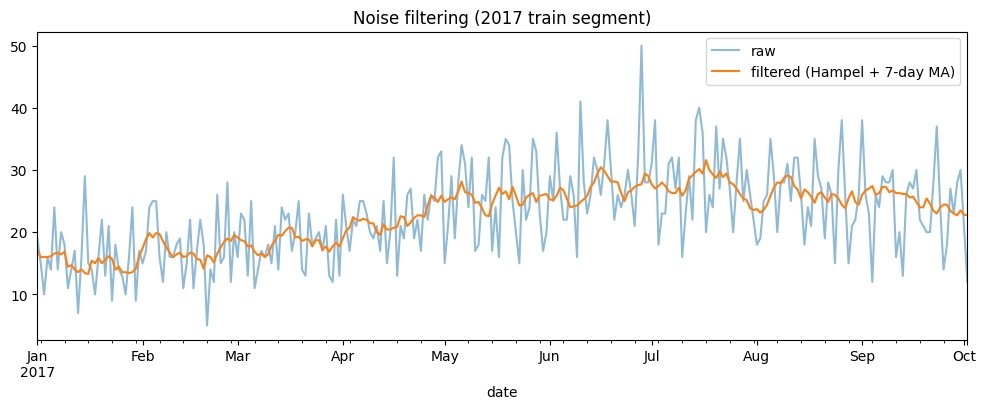

In [1]:
import pandas as pd, matplotlib.pyplot as plt

s = pd.read_csv("../data/series.csv", parse_dates=["date"], index_col="date")["sales"]

# split FIRST so the filter never touches test data
train, test = s.iloc[:-90], s.iloc[-90:]
print("train:", train.index.min().date(), "to", train.index.max().date(), len(train))
print("test: ", test.index.min().date(), "to", test.index.max().date(), len(test))

def hampel(x, window=7, n_sigma=3):
    med = x.rolling(window, center=True, min_periods=1).median()
    mad = (x - med).abs().rolling(window, center=True, min_periods=1).median()
    out = (x - med).abs() > n_sigma * 1.4826 * mad
    y = x.copy(); y[out] = med[out]
    return y, out

train_h, outliers = hampel(train)
train_f = train_h.rolling(7, center=True, min_periods=1).mean()
print("outliers replaced by Hampel:", int(outliers.sum()))

fig, ax = plt.subplots(figsize=(12, 4))
train["2017-01":].plot(ax=ax, alpha=0.5, label="raw")
train_f["2017-01":].plot(ax=ax, label="filtered (Hampel + 7-day MA)")
ax.legend(); ax.set_title("Noise filtering (2017 train segment)")
plt.savefig("../outputs/03_filtering.png", dpi=150)

train.rename("sales").to_csv("../data/train_raw.csv")
train_f.rename("sales").to_csv("../data/train_filtered.csv")
test.rename("sales").to_csv("../data/test_raw.csv")